<a href="https://colab.research.google.com/github/Aradhyagodambe/Python-Colab-Files/blob/main/DL_Fundamentals.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Types of Neural Networks
1. **Feedforward Neural Network (FNN/MLP)** – Data flows one way, input to output, no loops.
2. **Convolutional Neural Network (CNN)** – Uses filters to detect spatial patterns, mainly for images.
3. **Recurrent Neural Network (RNN)** – Has loops that retain memory of past inputs, good for sequences.
4. **Long Short-Term Memory (LSTM)** – An RNN with gates that remembers long-range dependencies.
5. **Gated Recurrent Unit (GRU)** – A simpler, faster LSTM alternative with fewer gates.
6. **Transformer** – Uses self-attention instead of recurrence; powers models like GPT and Claude.
7. **Autoencoder** – Compresses input then reconstructs it, used for compression or denoising.
8. **Variational Autoencoder (VAE)** – A probabilistic autoencoder that can generate new, similar data.
9. **Generative Adversarial Network (GAN)** – A generator and discriminator compete to produce realistic fake data.
10. **Graph Neural Network (GNN)** – Operates directly on graph data like social networks or molecules.
11. **Radial Basis Function Network (RBFN)** – Uses distance-based functions for fast approximation.
12. **Self-Organizing Map (SOM)** – Unsupervised network that clusters data into a low-dimensional map.
13. **Hopfield Network** – Recurrent network that stores and recalls patterns as memories.
14. **Restricted Boltzmann Machine (RBM)** – Stochastic two-layer network for unsupervised feature learning.
15. **Spiking Neural Network (SNN)** – Mimics biological neurons using discrete spikes over time.

# Difference between ML and DL


| Aspect | Machine Learning (ML) | Deep Learning (DL) |
|---|---|---|
| **Definition** | Algorithms that learn patterns from data | Subset of ML using multi-layered neural networks |
| **Data needed** | Works well with small/medium data | Needs large amounts of data |
| **Feature engineering** | Manual (done by humans) | Automatic (learned by the network) |
| **Hardware** | Runs fine on CPU | Needs GPU/TPU |
| **Training time** | Faster | Slower, more compute-heavy |
| **Interpretability** | More interpretable ("white box") | Less interpretable ("black box") |
| **Examples (algorithms)** | Linear Regression, Decision Trees, SVM, Random Forest | CNN, RNN, LSTM, Transformers, GANs |
| **Examples (applications)** | Spam detection, credit scoring, price prediction | Image recognition, speech recognition, ChatGPT, self-driving cars |

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import Perceptron
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("vatsalrakholiya/perceptron-data")

print("Path to dataset files:", path)

In [ ]:
P = pd.read_csv(f"{path}/placement.csv")

In [ ]:
P.head()

In [ ]:
P.shape

In [ ]:
P.columns

In [ ]:
X = P[['cgpa', 'resume_score']]
Y = P['placed']

In [ ]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.2, random_state = 42)

In [ ]:
model = Perceptron()
model.fit(X_train, Y_train)

In [ ]:
predict = model.predict(X_test)
predict

In [ ]:
score = accuracy_score(Y_test, predict)
print(score* 100)

In [ ]:
print(w := model.coef_ )

In [ ]:
print(b := model.intercept_ )

# Second dataset


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("abirhasan1703100/single-layer-perceptron-datasetsmall")

print("Path to dataset files:", path)

In [ ]:
SP = pd.read_csv(f'{path}/Single Layer Perceptron Dataset.csv')

In [ ]:
SP.isna().sum().sum()
SP = SP.dropna()
SP.isna().sum().sum()

In [ ]:
SP.columns

In [ ]:
X = SP[['Pattern', 'Feature1', 'Feature2', 'Feature3']]
Y = SP['Class_Label']

In [ ]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.2, random_state = 42)

In [ ]:
model = Perceptron()
model.fit(X_train, Y_train)

In [ ]:
pre = model.predict(X_test)
pre

In [ ]:
Sco = accuracy_score(Y_test, pre)
Sco

In [ ]:
model.coef_

In [ ]:
model.intercept_

# Activation Functions

| Category | Function | Formula | Range | Note |
|---|---|---|---|---|
| Classic | Sigmoid | 1/(1+e⁻ˣ) | (0, 1) | Saturates, kills gradients in deep nets |
| Classic | Tanh | (eˣ−e⁻ˣ)/(eˣ+e⁻ˣ) | (−1, 1) | Zero-centered, still saturates |
| ReLU family | ReLU | max(0, x) | [0, ∞) | Cheap, but neurons can "die" |
| ReLU family | Leaky ReLU | max(αx, x), α≈0.01 | (−∞, ∞) | Small gradient leaks through for x<0 |
| ReLU family | PReLU | max(αx, x), α learned | (−∞, ∞) | Leaky ReLU with a learnable slope |
| ReLU family | ELU | x if x>0, else α(eˣ−1) | (−α, ∞) | Smooth negative side, mean output → 0 |
| ReLU family | SELU | scaled ELU (fixed α, λ) | (−λα, ∞) | Self-normalizing across layers |
| Modern/smooth | GELU | x·Φ(x) | ≈(−0.17, ∞) | Probabilistic gate; default in BERT/GPT |
| Modern/smooth | Swish / SiLU | x·sigmoid(x) | ≈(−0.28, ∞) | Smooth, self-gated |
| Modern/smooth | Mish | x·tanh(softplus(x)) | ≈(−0.31, ∞) | Smooth, non-monotonic cousin of Swish |
| Modern/smooth | Softplus | ln(1+eˣ) | (0, ∞) | Smooth, everywhere-differentiable ReLU |
| Output layer | Softmax | eˣⁱ/Σeˣʲ | (0,1), sums to 1 | Class probabilities for multi-class output |
| Output layer | Linear (Identity) | x | (−∞, ∞) | No squashing; used for regression |
| Historical | Binary step | 1 if x≥0 else 0 | {0, 1} | Gradient is 0 everywhere — can't backprop |
| Historical | Maxout | max(w₁x+b₁, w₂x+b₂, …) | depends | Generalizes ReLU/Leaky ReLU, more params |

# ANN (Artificial Neural Network)

Type: Feedforward neural network

Architecture

* Every node in the input layer is connected to every node in the hidden layer, and every node in the hidden layer is connected to every node in the output layer (i.e., the layers are fully connected).

How it computes a prediction

1. Input → Hidden layer
For each hidden node, the incoming inputs and their weights are combined into a weighted sum, plus a bias term:

    z = x1w1 + x2w2 + ... + xnwn + bias

* Each hidden node has its own set of weights and its own bias, so this calculation is done separately for every node. The result is passed through an activation function to produce that node's output.

2. Hidden → Output layer
The hidden layer's outputs become the inputs to the output layer, where the same process — weighted sum, add bias, apply activation function — repeats.

3. Prediction
The output layer's activation function produces the network's final prediction value.

# Loss Function

Purpose: After the forward pass produces a prediction, the loss function measures how far that prediction is from the actual (true) value. This single number tells the network "how wrong" it was, and it's the value backpropagation uses to adjust weights and biases.

Common loss functions

1. Mean Squared Error (MSE) — used for regression (continuous outputs)

     MSE = (1/n) * Σ(y_actual − y_predicted)²

Squaring the error prevents positive and negative errors from cancelling out, and penalizes larger errors more heavily.

2. Cross-Entropy Loss (Log Loss) — used for classification

    Binary cross-entropy (2 classes):
Loss = −[y·log(p) + (1−y)·log(1−p)]
Categorical cross-entropy (multi-class): compares the predicted probability distribution across classes to the actual class.


Where it fits in training
* Forward pass → network produces a prediction
* Loss function → compares prediction vs. actual, outputs a single loss value
* Backpropagation → loss is used to compute gradients
* Weight/bias update (gradient descent) → weights adjust to reduce loss

This repeats over many epochs until the loss is minimized.

# ANN Model

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("filippoo/deep-learning-az-ann")

print("Path to dataset files:", path)

In [ ]:
D = pd.read_csv(f"{path}/Churn_Modelling.csv")

In [ ]:
D.head()

In [ ]:
D.shape

In [ ]:
D.isna().sum().sum()

D.duplicated().sum()

In [ ]:
LE = LabelEncoder()

D['Geography'] = LE.fit_transform(D['Geography'])
D['Gender'] = LE.fit_transform(D['Gender'])

D[['Geography','Gender']].head(2)

D = D.drop(columns=['RowNumber','CustomerId','Surname'])

In [ ]:
D.head()

In [ ]:
D.columns

X = D[['CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
      'IsActiveMember', 'EstimatedSalary']]
Y = D['Exited']

In [ ]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [ ]:
model = Sequential()

In [ ]:
model.add(Dense(8, input_dim = 10, activation = 'relu'))
model.add(Dense(7, activation = 'relu'))
model.add(Dense(1, activation = 'sigmoid'))

In [ ]:
model.compile(
    optimizer = 'adam',
    loss = 'binary_crossentropy',
    metrics = ['accuracy']
)

In [ ]:
model.fit(X_train, Y_train, epochs = 100, verbose = 1)

In [ ]:
predict = model.predict(X_test)
print(pre := np.where(predict >= 0.5, 1, 0).ravel())

print((scr := accuracy_score(Y_test, pre))* 100)

# CNN

Architecture Of CNN

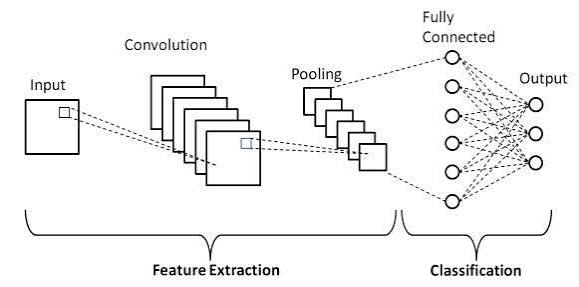

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPool2D, Flatten, Dense
from tensorflow.keras.datasets import mnist

In [ ]:
(train_images, train_lables), (test_images, test_lables) = mnist.load_data()

In [ ]:
train_images = train_images/255
test_images = test_images/255

In [ ]:
train_images[4]

In [ ]:
train_images = train_images.reshape((60000,28,28,1))
test_images = test_images.reshape((10000,28,28,1))

In [ ]:
model = Sequential()

model.add(Conv2D(32,(3,3),activation = 'relu'))
model.add(MaxPool2D(2,2))
model.add(Flatten())
model.add(Dense(10, activation = 'softmax'))

In [ ]:
model.compile(
    optimizer = 'adam',
    loss = 'sparse_categorical_crossentropy',
    metrics = ['accuracy']
)

In [ ]:
model.fit(train_images, train_lables, epochs = 10)

In [ ]:
pre = model.predict(test_images[0].reshape(1,28,28,1))
pre

In [ ]:
predict = np.argmax(pre)
print(predict)

In [ ]:
print(test_lables[0])

In [ ]:
loss, acc = model.evaluate(test_images, test_lables)
print("Accuracy", acc*100)

# RNN

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Dense, SimpleRNN
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
import re

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("uciml/sms-spam-collection-dataset")

print("Path to dataset files:", path)

In [ ]:
S = pd.read_csv(f"{path}/spam.csv", encoding = 'latin')

In [ ]:
S = S.drop_duplicates()
S.duplicated().sum()

In [ ]:
S.isna().sum()

In [ ]:
S.columns

In [ ]:
S = S.drop(columns = ['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'])

In [ ]:
S['v2'][8]

In [ ]:
def clean(text):
  text = re.sub(r'<.*?>', '', text)
  text = re.sub(r'[^a-zA-Z\s]', '', text)
  text = re.sub(r'\s+', ' ', text)
  text = text.lower()
  return text

In [ ]:
S['v2'] = S['v2'].apply(clean)

In [ ]:
LE = LabelEncoder()

S['v1'] = LE.fit_transform(S['v1'])

In [ ]:
X = S['v2']

Y = S['v1']

In [ ]:
tokenizer = Tokenizer(num_words= 5000,)
tokenizer.fit_on_texts(X)

X_seq = tokenizer.texts_to_sequences(X)

In [ ]:
print(tokenizer.word_index)

In [ ]:
for sen, seq in zip(X, X_seq):
  print("sentence", sen, "\n", "sequence", seq, "\n")

In [ ]:
X_pad = pad_sequences(X_seq, maxlen = 50)

In [ ]:
X_train, X_test, Y_train, Y_test = train_test_split(X_pad, Y, test_size = 0.2, random_state = 42)

In [ ]:
model = Sequential()

model.add(Embedding(5000, 32))
model.add(SimpleRNN(32))
model.add(Dense(1, activation = 'sigmoid'))

In [ ]:
model.compile(
    optimizer = 'adam',
    loss = 'binary_crossentropy',
    metrics = ['accuracy']
)

In [ ]:
model.fit(X_train, Y_train, epochs = 20)

In [ ]:
print(predict := model.predict(X_test))

In [ ]:
loss, acc = model.evaluate(X_test, Y_test)
print(loss, acc)

# Object Detection Models

In [ ]:
# !pip install -qU ultralytics

# For image

In [ ]:
from ultralytics import YOLO

model = YOLO('yolo11n.pt')

result = model("/content/Screenshot 2026-08-26 125106.png")

result[0].show()

# For video

In [ ]:
from ultralytics import YOLO

model = YOLO('yolo11n.pt')

result = model("/content/Screenshot 2026-08-26 125106.png",save = True)